Exploración y consolidación de créditos, ahorro y mercado laboral


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Funciona si el notebook está en la misma carpeta que los CSV o en la carpeta superior.
BASE = Path.cwd()
if not (BASE / 'D_CREDITOS.csv').exists() and (BASE.parent / 'D_CREDITOS.csv').exists():
    BASE = BASE.parent
ARCHIVOS = { 'creditos':'D_CREDITOS.csv', 'ahorro':'P_AHORRO.csv', 'laboral':'N_MERCADO_LABORAL.csv' }
for archivo in ARCHIVOS.values():
    if not (BASE / archivo).exists():
        raise FileNotFoundError(f'Falta {archivo} en {BASE}. Pon los tres CSV junto al notebook.')
OUT = BASE / 'salidas'
OUT.mkdir(exist_ok=True)
print('Carpeta de datos:', BASE)

Carpeta de datos: /content


## 1. Carga y verificación estructural


In [3]:
datos = {nombre: pd.read_csv(BASE / archivo, sep='|', dtype='string', low_memory=False) for nombre, archivo in ARCHIVOS.items()}
creditos, ahorro, laboral = (datos[k] for k in ('creditos','ahorro','laboral'))
resumen = pd.DataFrame([{'base':k,'filas':len(v),'columnas':v.shape[1], 'hogares_unicos':v['DIRECTORIO'].nunique()} for k,v in datos.items()])
display(resumen)
for nombre, df in datos.items():
    assert 'DIRECTORIO' in df, f'Falta identificador en {nombre}'
    print(nombre, ':', ', '.join(df.columns[:12]), '...')

,base,filas,columnas,hogares_unicos
0,creditos,4341,26,3250
1,ahorro,26950,35,14981
2,laboral,32956,125,15432


creditos : DIRECTORIO, CONSECUTIVO_DANE_2010, CONSECUTIVO_DANE_2013, CONSECUTIVO_DANE_2016, CONSECUTIVO_DANE_ELPS_2012, CONSECUTIVO_DANE_ELPS_2015, CONSECUTIVO_DANE_ELCO_2019, CONSECUTIVO_DANE_ELCO_2022, SECUENCIA_ENCUESTA, SECUENCIA_P, ORDEN, P2097 ...
ahorro : DIRECTORIO, ORDEN, CONSECUTIVO_DANE_2010, CONSECUTIVO_DANE_2010_PER, CONSECUTIVO_DANE_2013, CONSECUTIVO_DANE_2013_PER, CONSECUTIVO_DANE_2016, CONSECUTIVO_DANE_2016_PER, CONSECUTIVO_DANE_ELPS_2012, CONSECUTIVO_DANE_ELPS_PER_2012, CONSECUTIVO_DANE_ELPS_2015, CONSECUTIVO_DANE_ELPS_PER_2015 ...
laboral : DIRECTORIO, ORDEN, CONSECUTIVO_DANE_2010, CONSECUTIVO_DANE_2010_PER, CONSECUTIVO_DANE_2013, CONSECUTIVO_DANE_2013_PER, CONSECUTIVO_DANE_2016, CONSECUTIVO_DANE_2016_PER, CONSECUTIVO_DANE_ELPS_2012, CONSECUTIVO_DANE_ELPS_PER_2012, CONSECUTIVO_DANE_ELPS_2015, CONSECUTIVO_DANE_ELPS_PER_2015 ...


## 2. Diccionario de trabajo y validación de categorías


In [4]:
diccionario = pd.DataFrame([
  ('D_CREDITOS','P2110','¿Está al día en el pago del crédito?','1 = Sí; 2 = No; 3 = No ha iniciado pago','Objetivo de clasificación'),
  ('D_CREDITOS','P2104','Valor inicial del crédito','Valor monetario','Descriptiva / posible predictor'),
  ('D_CREDITOS','P2105S1','Monto de la cuota','Valor monetario si aplica','Descriptiva / posible predictor'),
  ('D_CREDITOS','P2107S1','Plazo en meses','Número de meses si aplica','Descriptiva / posible predictor'),
  ('P_AHORRO','P2431','Hábito de ahorro','1 = Sí; 2 = No; 3 = No recibe ingresos','Indicador de ahorro'),
  ('P_AHORRO','P2441','Tenencia de cuenta financiera','1 = Sí; 2 = No','Indicador de acceso financiero'),
  ('N_MERCADO_LABORAL','P6240','Actividad durante semana anterior','1 = Trabajó al menos una hora en actividad remunerada; revisar otras categorías','Indicador laboral')
], columns=['fuente','codigo','descripcion','codificacion_de_trabajo','uso'])
display(diccionario)
for origen, var in [('creditos','P2110'),('ahorro','P2431'),('ahorro','P2441'),('laboral','P6240')]:
    print(f'\n{origen}.{var}:')
    display(datos[origen][var].value_counts(dropna=False).rename_axis('codigo').reset_index(name='frecuencia'))
# Comprobar códigos esperados en las variables recodificadas
assert set(creditos['P2110'].dropna().unique()).issubset({'1','2','3'})
assert set(ahorro['P2431'].dropna().unique()).issubset({'1','2','3'})
assert set(ahorro['P2441'].dropna().unique()).issubset({'1','2'})

,fuente,codigo,descripcion,codificacion_de_trabajo,uso
0,D_CREDITOS,P2110,¿Está al día en el pago del crédito?,1 = Sí; 2 = No; 3 = No ha iniciado pago,Objetivo de clasificación
1,D_CREDITOS,P2104,Valor inicial del crédito,Valor monetario,Descriptiva / posible predictor
2,D_CREDITOS,P2105S1,Monto de la cuota,Valor monetario si aplica,Descriptiva / posible predictor
3,D_CREDITOS,P2107S1,Plazo en meses,Número de meses si aplica,Descriptiva / posible predictor
4,P_AHORRO,P2431,Hábito de ahorro,1 = Sí; 2 = No; 3 = No recibe ingresos,Indicador de ahorro
5,P_AHORRO,P2441,Tenencia de cuenta financiera,1 = Sí; 2 = No,Indicador de acceso financiero
6,N_MERCADO_LABORAL,P6240,Actividad durante semana anterior,1 = Trabajó al menos una hora en actividad rem...,Indicador laboral



creditos.P2110:


,codigo,frecuencia
0,1,3432
1,2,700
2,3,209



ahorro.P2431:


,codigo,frecuencia
0,2,18316
1,3,5671
2,1,2963



ahorro.P2441:


,codigo,frecuencia
0,2,19503
1,1,7447



laboral.P6240:


,codigo,frecuencia
0,5,17584
1,1,13889
2,4,722
3,3,461
4,2,300


## 3. Calidad de datos: faltantes y duplicados


In [5]:
for nombre, df in datos.items():
    print(f'\n{nombre}: {len(df):,} filas, {df.duplicated().sum():,} filas idénticas')
    faltantes = df.isna().sum().sort_values(ascending=False).head(12)
    display(pd.DataFrame({'nulos':faltantes, 'porcentaje':(100*faltantes/len(df)).round(1)}))
cols_interes = ['P2110','P2104','P2105S1','P2107S1','P2108']
display(pd.DataFrame({'nulos':creditos[cols_interes].isna().sum(), 'porcentaje':(creditos[cols_interes].isna().mean()*100).round(2)}))


creditos: 4,341 filas, 2 filas idénticas


,nulos,porcentaje
P2107S2,4339,100.0
CONSECUTIVO_DANE_ELPS_2015,2899,66.8
CONSECUTIVO_DANE_2013,2428,55.9
CONSECUTIVO_DANE_2016,2409,55.5
CONSECUTIVO_DANE_2010,2342,54.0
CONSECUTIVO_DANE_ELPS_2012,1997,46.0
CONSECUTIVO_DANE_ELCO_2019,258,5.9
P2105S1,192,4.4
P2107S1,175,4.0
P2109S1,76,1.8



ahorro: 26,950 filas, 0 filas idénticas


,nulos,porcentaje
P2437S12,26909,99.8
P2437S5,26898,99.8
P2437S4,26875,99.7
P2437S8,26837,99.6
P2437S7,26782,99.4
P2437S6,26777,99.4
P2437S3,26720,99.1
P2437S9,26707,99.1
P2437S10,26692,99.0
P2437S2,26455,98.2



laboral: 32,956 filas, 0 filas idénticas


,nulos,porcentaje
P2363S8,32956,100.0
P2363S7,32951,100.0
P187S5A1,32944,100.0
P2363S5,32930,99.9
P165S4A2,32925,99.9
P165S4A1,32925,99.9
P164S1,32920,99.9
P169S2A2,32894,99.8
P169S2A1,32894,99.8
P2363S6,32893,99.8


,nulos,porcentaje
P2110,0,0.00
P2104,0,0.00
P2105S1,192,4.42
P2107S1,175,4.03
P2108,0,0.00


## 4. Recodificación y agregación a nivel de hogar


In [6]:
ah = ahorro[['DIRECTORIO','P2431','P2441']].copy()
ah['indic_ahorra'] = ah['P2431'].eq('1').fillna(False).astype(int)
ah['indic_con_ingresos'] = ah['P2431'].isin(['1','2']).astype(int)
ah['indic_cuenta'] = ah['P2441'].eq('1').fillna(False).astype(int)
agg_ah = ah.groupby('DIRECTORIO', as_index=False).agg(
    n_personas_ahorro=('P2431','size'), n_personas_con_ingresos=('indic_con_ingresos','sum'),
    n_personas_que_ahorran=('indic_ahorra','sum'), n_personas_con_cuenta=('indic_cuenta','sum'))
agg_ah['prop_que_ahorran_sobre_con_ingresos'] = (agg_ah['n_personas_que_ahorran']/agg_ah['n_personas_con_ingresos'].replace(0,np.nan))

la = laboral[['DIRECTORIO','P6240']].copy()
la['indic_trabajo_semana'] = la['P6240'].eq('1').fillna(False).astype(int)
agg_la = la.groupby('DIRECTORIO', as_index=False).agg(n_personas_laboral=('P6240','size'),n_personas_trabajo_semana=('indic_trabajo_semana','sum'))
assert not agg_ah.DIRECTORIO.duplicated().any()
assert not agg_la.DIRECTORIO.duplicated().any()
print('Tablas resumidas:', agg_ah.shape, agg_la.shape)
display(agg_ah.head(3))

Tablas resumidas: (14981, 6) (15432, 3)


,DIRECTORIO,n_personas_ahorro,n_personas_con_ingresos,n_personas_que_ahorran,n_personas_con_cuenta,prop_que_ahorran_sobre_con_ingresos
0,1336000,1,1,0,0,0.0
1,1336001,2,1,0,1,0.0
2,1336002,1,1,0,0,0.0


## 5. Consolidación de las fuentes


In [7]:
n_original = len(creditos)
cr = creditos[creditos['P2110'].isin(['1','2'])].copy()
cr['objetivo_atraso'] = cr['P2110'].eq('2').astype(int)
consolidada = cr.merge(agg_ah,on='DIRECTORIO',how='inner',validate='many_to_one').merge(agg_la,on='DIRECTORIO',how='inner',validate='many_to_one')
assert len(consolidada) <= len(cr), 'La unión no debe multiplicar créditos'
assert consolidada['objetivo_atraso'].notna().all()
print(f'Inicial: {n_original:,}; inicio de pago registrado: {len(cr):,}; consolidados: {len(consolidada):,}')
print('Hogares consolidados:',consolidada.DIRECTORIO.nunique(), '| Columnas:',len(consolidada.columns))
display(consolidada['objetivo_atraso'].value_counts().rename(index={0:'Al día',1:'Con retraso'}).to_frame('creditos'))
print('Filas idénticas en la consolidada:',consolidada.duplicated().sum())

Inicial: 4,341; inicio de pago registrado: 4,132; consolidados: 4,013
Hogares consolidados: 3020 | Columnas: 34


,creditos
objetivo_atraso,
Al día,3338
Con retraso,675


Filas idénticas en la consolidada: 2


## 6. Exploración descriptiva y visualizaciones


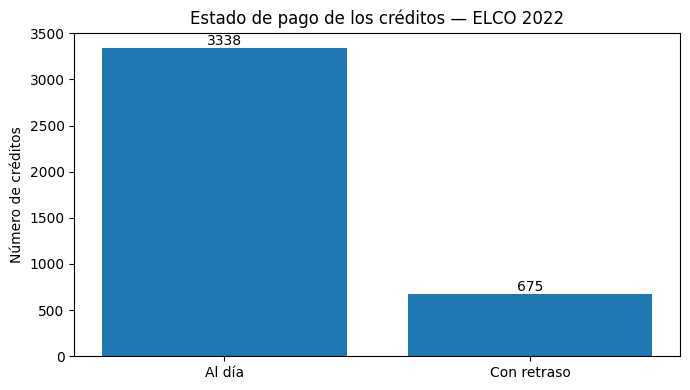

,creditos,atrasados,proporcion,porcentaje_atraso
grupo,,,,
Sin personas que ahorran,3075,594,0.193171,19.32
Con personas que ahorran,938,81,0.086354,8.64


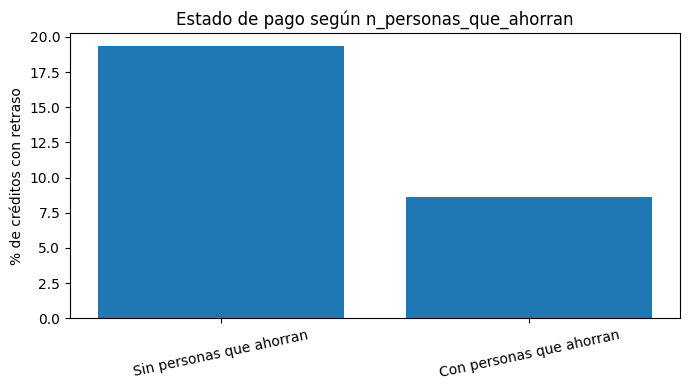

,creditos,atrasados,proporcion,porcentaje_atraso
grupo,,,,
Sin personas con cuenta,1533,370,0.241357,24.14
Con personas con cuenta,2480,305,0.122984,12.30


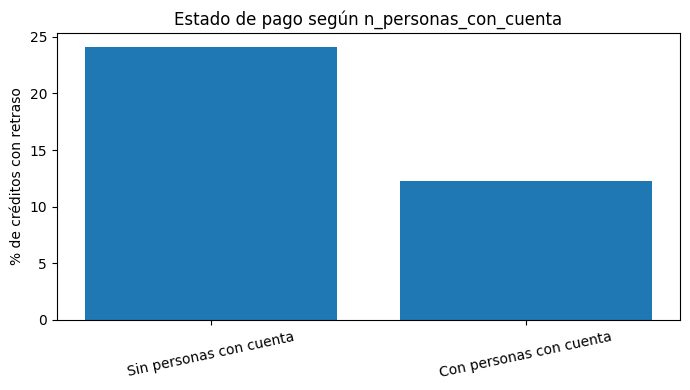

,creditos,atrasados,proporcion,porcentaje_atraso
grupo,,,,
Sin personas que trabajan,810,132,0.162963,16.30
Con personas que trabajan,3203,543,0.169529,16.95


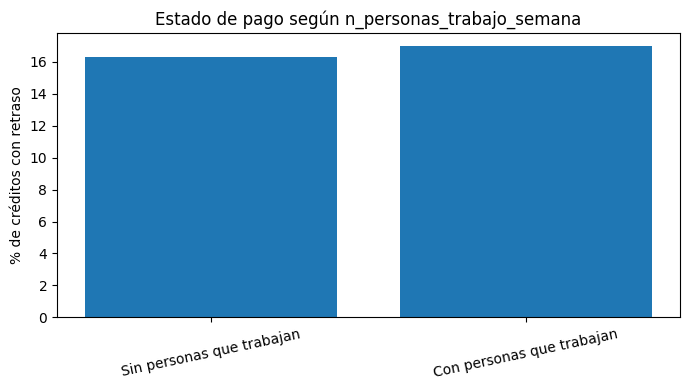

In [8]:
dist=consolidada['objetivo_atraso'].value_counts().reindex([0,1],fill_value=0)
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(['Al día','Con retraso'],dist.values)
ax.set(ylabel='Número de créditos',title='Estado de pago de los créditos — ELCO 2022')
for i,v in enumerate(dist.values): ax.text(i,v,str(v),ha='center',va='bottom')
plt.tight_layout(); fig.savefig(OUT/'01_estado_creditos.png',dpi=160); plt.show()
for col, nombres, salida in [
 ('n_personas_que_ahorran',['Sin personas que ahorran','Con personas que ahorran'],'02_ahorro_atraso.png'),
 ('n_personas_con_cuenta',['Sin personas con cuenta','Con personas con cuenta'],'03_cuenta_atraso.png'),
 ('n_personas_trabajo_semana',['Sin personas que trabajan','Con personas que trabajan'],'04_trabajo_atraso.png')]:
    grupo=np.where(consolidada[col].gt(0),nombres[1],nombres[0]); aux=consolidada.assign(grupo=grupo)
    tab=aux.groupby('grupo').agg(creditos=('objetivo_atraso','size'),atrasados=('objetivo_atraso','sum'),proporcion=('objetivo_atraso','mean')).reindex(nombres)
    display(tab.assign(porcentaje_atraso=(tab.proporcion*100).round(2)))
    fig,ax=plt.subplots(figsize=(7,4)); ax.bar(tab.index,100*tab.proporcion)
    ax.set(ylabel='% de créditos con retraso',title='Estado de pago según '+col)
    ax.tick_params(axis='x',rotation=12)
    plt.tight_layout();fig.savefig(OUT/salida,dpi=160);plt.show()

## 7. Características monetarias y faltantes


In [9]:
montos=['P2104','P2105S1','P2107S1','P2108']
for c in montos:consolidada[c+'_numerico']=pd.to_numeric(consolidada[c],errors='coerce')
medianas=consolidada.groupby('objetivo_atraso')[[x+'_numerico' for x in montos]].median().T
medianas.columns=['Al día','Con retraso']
display(medianas)
display(consolidada[[x+'_numerico' for x in montos]].isna().sum().to_frame('valores_faltantes'))

,Al día,Con retraso
P2104_numerico,9000000.0,4000000.0
P2105S1_numerico,400000.0,250000.0
P2107S1_numerico,48.0,36.0
P2108_numerico,4732500.0,2050000.0


,valores_faltantes
P2104_numerico,0
P2105S1_numerico,135
P2107S1_numerico,128
P2108_numerico,0


## 8. Exportación y controles de reproducibilidad


In [10]:
consolidada.to_csv(OUT/'ELCO_2022_consolidado_reproducible.csv',index=False,encoding='utf-8-sig')
diccionario.to_csv(OUT/'diccionario_variables_trabajo.csv',index=False,encoding='utf-8-sig')
resumen.to_csv(OUT/'resumen_archivos.csv',index=False,encoding='utf-8-sig')
print('Exportaciones creadas:')
for f in sorted(OUT.iterdir()): print(f.name, f.stat().st_size,'bytes')

Exportaciones creadas:
01_estado_creditos.png 39291 bytes
02_ahorro_atraso.png 52307 bytes
03_cuenta_atraso.png 46915 bytes
04_trabajo_atraso.png 50440 bytes
ELCO_2022_consolidado_reproducible.csv 660819 bytes
diccionario_variables_trabajo.csv 806 bytes
resumen_archivos.csv 106 bytes
